# SmartRetail — Model Training & Results
### A simple notebook for project presentation

**Objective:** estimate the next 28 days of recorded sales for established products in observed countries, and explore comparable products for a new-product pilot.

**Method:** real transaction records → clean sales → past-sales features → train models → compare with a baseline → explain results.

This presentation covers the core product-demand model and a launch example. The [full research notebook](https://colab.research.google.com/github/Rehan-2024/SmartRetailing/blob/main/notebooks/SmartRetail_All_Models_Colab.ipynb) contains the wider nine-method comparison, seasonal checks and separate academic models.

**How to use:** open in Colab, select **Runtime → Run all**, and authorize your Drive mount. Saved outputs below are from an actual local execution, so results can also be shown without rerunning. CPU is sufficient. The million-row Excel file can take several minutes to read.

## 1. Setup and dataset

We use **Online Retail II**: real transactions from a UK retailer, recorded during 2009–2011. It is an open dataset with a **CC BY 4.0** license: [Chen, D. (2012), UCI](https://doi.org/10.24432/C5CG6D).

The workbook is in [SmartRetailData on Drive](https://drive.google.com/drive/folders/1cp5PzhIxOnkND4waySrPrOR3vw9fC-L7). This notebook needs only that workbook. It does not train on campaign, store or geographic files with unverified provenance. No synthetic or augmented training rows are used.

In [1]:
import os, sys, json, hashlib, importlib.util
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "numpy==2.3.5", "pandas==3.0.2", "scikit-learn==1.8.0",
        "openpyxl==3.1.5", "matplotlib==3.10.8"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython import get_ipython
from IPython.display import display
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_ROOT = Path("/content/drive/MyDrive/SmartRetailData")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/SmartRetailResults/Presentation")
else:
    DATA_ROOT = Path(os.environ.get("SMART_RETAIL_DATA_ROOT", str(Path.cwd().parent)))
    OUTPUT_ROOT = Path.cwd() / "artifacts" / "presentation-run"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
WORKBOOK = DATA_ROOT / "transactions/online_retail_II.xlsx"
print("Dataset:", WORKBOOK)
print("Results:", OUTPUT_ROOT)

Dataset: D:\AML\transactions\online_retail_II.xlsx
Results: D:\AML\SmartRetailing\artifacts\presentation-run


In [2]:
EXPECTED_SHA256 = 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980'
assert WORKBOOK.is_file(), "The workbook was not found. Check the mounted Drive account and DATA_ROOT."
assert hashlib.sha256(WORKBOOK.read_bytes()).hexdigest() == EXPECTED_SHA256, "Input differs from the verified UCI original."
print("Verified: workbook bytes match the official UCI dataset.")

Verified: workbook bytes match the official UCI dataset.


## 2. Clean the transaction records

Read both workbook sheets, remove exact duplicates, and keep positive merchandise sales. Cancellations, returns, fees and postage are excluded from this **gross unit-sales target**. It is not net revenue or unconstrained demand. Customer IDs are not model features.

In [3]:
NON_PRODUCTS={'ADJUST','ADJUST2','AMAZONFEE','B','BANK CHARGES','C2','CRUK','D','DOT','M','PADS','POST','S','TEST001','TEST002'}

raw = pd.concat(pd.read_excel(WORKBOOK, sheet_name=None).values(), ignore_index=True)
raw_rows = len(raw)
frame = raw.drop_duplicates().copy()
duplicates = raw_rows - len(frame)
del raw
frame["InvoiceDate"] = pd.to_datetime(frame.InvoiceDate, errors="coerce")
frame["StockCode"] = frame.StockCode.astype(str).str.strip()
frame["Description"] = frame.Description.astype("string").str.strip()

is_merchandise = (
    ~frame.StockCode.str.upper().isin(NON_PRODUCTS)
    & ~frame.Description.str.upper().fillna("").str.contains(
        "POSTAGE|DOTCOM|BANK CHARGE|AMAZON FEE|MANUAL|CARRIAGE|ADJUSTMENT", regex=True)
)
valid = (is_merchandise & frame.Quantity.gt(0) & frame.Price.gt(0)
         & frame.InvoiceDate.notna() & ~frame.Invoice.astype(str).str.upper().str.startswith("C"))
sales = frame.loc[valid].copy()
sales["Country"] = sales.Country.fillna("Unknown")
sales["date"] = sales.InvoiceDate.dt.floor("D")
del frame

audit_table = pd.DataFrame({"Check": ["Original rows", "Exact duplicates removed", "Usable merchandise sales", "Product codes", "Observed countries"],
    "Value": [raw_rows, duplicates, len(sales), sales.StockCode.nunique(), sales.Country.nunique()]})
display(audit_table)
print("Recorded period:", sales.date.min().date(), "to", sales.date.max().date())

,Check,Value
0,Original rows,1067371
1,Exact duplicates removed,34335
2,Usable merchandise sales,1003117
3,Product codes,4886
4,Observed countries,43


Recorded period: 2009-12-01 to 2011-12-09


## 3. Create features and chronological partitions

**One prediction:** units for one product–country pair over the following 28 days.

The existing model uses preceding 7/28/84-day sales, the previous 28 days, active sales days, observed product age, initial price and seasonal position. The challenger adds past orders, variability, time since the last sale and annual sales history. Features always end **before** their forecast begins.

Only pairs with at least **84 days of history and 10 preceding-84-day order occurrences** are evaluated. Unrecorded days are filled with zero sales; availability and stockouts are unknown.

In [4]:
dates = pd.date_range(sales.date.min(), sales.date.max())
pairs = (sales.sort_values("InvoiceDate").groupby(["StockCode", "Country"])
         .agg(price=("Price", "first")).reset_index())
pair_keys = list(zip(pairs.StockCode, pairs.Country))
pair_index = {key: i for i, key in enumerate(pair_keys)}
day_index = {day: i for i, day in enumerate(dates)}
units = np.zeros((len(pairs), len(dates)))
orders = np.zeros_like(units)
daily = sales.groupby(["StockCode", "Country", "date"]).agg(units=("Quantity", "sum"), orders=("Invoice", "nunique"))
for (product, country, day), row in daily.iterrows():
    i, j = pair_index[(product, country)], day_index[day]
    units[i, j], orders[i, j] = row["units"], row["orders"]

first = np.argmax(units > 0, axis=1)
prices = pairs.price.to_numpy()
evaluation_origins = list(range(len(dates) - 112, len(dates), 28))
train_origins = list(range(112, evaluation_origins[0] - 27, 28))
roles = ["Validation 1", "Validation 2", "Calibration", "Reused historical test"]

def eligible(origin):
    return (first <= origin - 84) & (orders[:, origin-84:origin].sum(axis=1) >= 10)

display(pd.DataFrame([{"Partition": role, "Forecast from": str(dates[o].date()),
    "Forecast through": str(dates[o+27].date()), "Eligible pairs": int(eligible(o).sum())}
    for role, o in zip(roles, evaluation_origins)]))
assert train_origins[-1] + 27 < evaluation_origins[0]

,Partition,Forecast from,Forecast through,Eligible pairs
0,Validation 1,2011-08-20,2011-09-16,1660
1,Validation 2,2011-09-17,2011-10-14,1817
2,Calibration,2011-10-15,2011-11-11,1861
3,Reused historical test,2011-11-12,2011-12-09,1975


In [5]:
# Exact feature calculation used by the project.
def feature_matrix(units,origin,prices,first,orders=None,rich=False):
    last28=units[:,origin-28:origin].sum(1)
    prev28=units[:,origin-56:origin-28].sum(1)
    last84=units[:,origin-84:origin].sum(1)
    recent7=units[:,origin-7:origin].sum(1)
    active=(units[:,origin-84:origin]>0).sum(1)
    base=np.column_stack([np.log1p(last28),np.log1p(prev28),np.log1p(last84),np.log1p(recent7),active,np.maximum(0,origin-first),np.log1p(prices),np.full(len(prices),(origin%365)/365)])
    if not rich: return base
    history=units[:,origin-84:origin]; last_sale=np.where((history>0).any(1),np.argmax((history>0)[:,::-1],axis=1),84)
    # All aggregates end strictly before the prediction origin, including annual lag.
    annual=units[:,origin-365:origin-337].sum(1) if origin>=365 else np.zeros(len(prices))
    recent_orders=orders[:,origin-28:origin].sum(1); old_orders=orders[:,origin-84:origin-28].sum(1)
    seasonal=2*np.pi*origin/365.25
    return np.column_stack([base,np.log1p(units[:,origin-84:origin-56].sum(1)),np.log1p(history.max(1)),np.log1p(history.std(1)),last_sale,
        np.log((last28+1)/(prev28+1)),np.log1p(recent_orders),np.log1p(old_orders),np.log1p(last28/(recent_orders+1)),np.log1p(annual),
        np.full(len(prices),origin>=365),np.full(len(prices),np.sin(seasonal)),np.full(len(prices),np.cos(seasonal))])

base_batches, history_batches, targets = [], [], []
for origin in train_origins:
    mask = eligible(origin)
    base_batches.append(feature_matrix(units, origin, prices, first)[mask])
    history_batches.append(feature_matrix(units, origin, prices, first, orders, True)[mask])
    targets.append(units[mask, origin:origin+28].sum(axis=1))

X_train = np.concatenate(base_batches)
X_history = np.concatenate(history_batches)
y_train = np.concatenate(targets)
print(f"Training examples: {len(y_train):,}")
print("Existing-model features:", X_train.shape[1], "| Challenger features:", X_history.shape[1])

Training examples: 30,205
Existing-model features: 8 | Challenger features: 20


## 4. Train our models

**Baseline:** repeat the previous 28 days of unit sales. It requires no fitting.

**Existing project model:** histogram gradient boosting trained on `log(1 + units)`. The log target reduces the influence of unusually large orders; predictions are converted back into units.

**Challenger:** gradient boosting trained to minimize absolute error, with the richer history features. The following cell performs the actual `.fit()` calls. These are the same model settings used in the full project, not a new accuracy-tuning experiment.

In [6]:
model = HistGradientBoostingRegressor(
    max_iter=160, max_leaf_nodes=15, l2_regularization=5, random_state=42)
model.fit(X_train, np.log1p(y_train))

challenger = HistGradientBoostingRegressor(
    loss="absolute_error", max_iter=240, max_leaf_nodes=15,
    l2_regularization=10, random_state=42)
challenger.fit(X_history, y_train)

print("Trained existing model and challenger on real historical sales.")

Trained existing model and challenger on real historical sales.


## 5. Evaluate and explain the results

**MAE:** average absolute error in units per product–country pair per 28 days. **WAPE:** total absolute unit error divided by actual units. **RMSE:** penalizes large mistakes more strongly. Lower is better; WAPE is **not an accuracy score**.

Two earlier validation windows compare the methods. The next window calibrates an empirical band. The last period has already been inspected in earlier development, so it is explicitly a **reused historical benchmark**, not an untouched independent test. The project retains the existing model if the validation winner worsens either benchmark WAPE or RMSE. That release decision uses known benchmark results.

In [7]:
def metrics(actual,pred):
    error=np.abs(actual-pred)
    return {'mae':float(error.mean()),'wape':float(error.sum()/actual.sum()) if actual.sum()>0 else None,'rmse':float(np.sqrt(((actual-pred)**2).mean())),'rows':len(actual)}

EXISTING = "Existing gradient boosting"
CHALLENGER = "History challenger"
BASELINE = "Repeat last 28 days"
results = {name: [] for name in [BASELINE, EXISTING, CHALLENGER]}

for origin in evaluation_origins:
    mask = eligible(origin)
    actual = units[mask, origin:origin+28].sum(axis=1)
    predictions = {
        BASELINE: units[mask, origin-28:origin].sum(axis=1),
        EXISTING: np.maximum(0, np.expm1(model.predict(feature_matrix(units, origin, prices, first)[mask]))),
        CHALLENGER: np.maximum(0, challenger.predict(feature_matrix(units, origin, prices, first, orders, True)[mask]))
    }
    for name, prediction in predictions.items():
        results[name].append((actual, prediction))

rows = []
for name, windows in results.items():
    validation = metrics(np.concatenate([a for a, p in windows[:2]]), np.concatenate([p for a, p in windows[:2]]))
    test = metrics(*windows[-1])
    rows.append({"Method": name, "Validation MAE": validation["mae"], "Test MAE": test["mae"],
                 "Test WAPE (%)": test["wape"]*100, "Test RMSE": test["rmse"], "Test pairs": test["rows"]})
result_table = pd.DataFrame(rows)
display(result_table.round(2))

validation_winner = min(rows, key=lambda r: r["Validation MAE"])["Method"]
winner_test = metrics(*results[validation_winner][-1])
existing_test = metrics(*results[EXISTING][-1])
passes_guard = winner_test["wape"] <= existing_test["wape"] and winner_test["rmse"] <= existing_test["rmse"]
deployed = validation_winner if passes_guard else EXISTING
print("Validation winner:", validation_winner)
print("Kept in the app:", deployed)
print("The challenger is not promoted when its known-benchmark errors regress.")

,Method,Validation MAE,Test MAE,Test WAPE (%),Test RMSE,Test pairs
0,Repeat last 28 days,108.46,120.23,45.54,286.98,1975
1,Existing gradient boosting,100.24,118.33,44.81,357.34,1975
2,History challenger,94.37,129.47,49.04,386.27,1975


Validation winner: History challenger
Kept in the app: Existing gradient boosting
The challenger is not promoted when its known-benchmark errors regress.


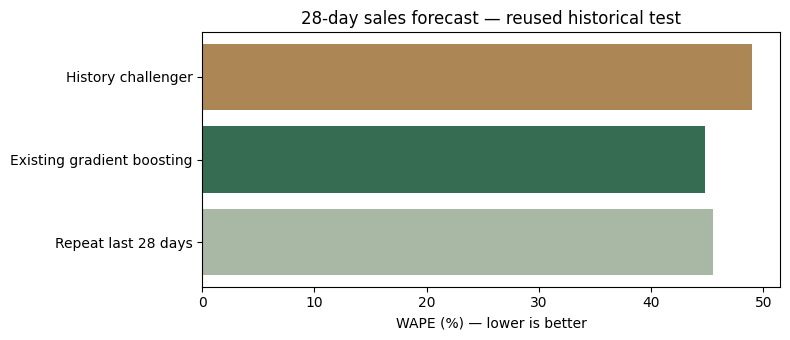

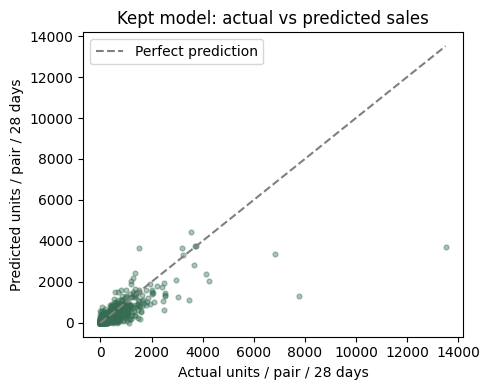

Empirical-band coverage: 80.2%; nominal target: 80%.
Bands are calibrated historical ranges, not guaranteed future confidence.


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(result_table["Method"], result_table["Test WAPE (%)"], color=["#a8b8a4", "#356c52", "#ad8656"])
ax.set(title="28-day sales forecast — reused historical test", xlabel="WAPE (%) — lower is better")
plt.tight_layout(); plt.show()

actual, predicted = results[deployed][-1]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(actual, predicted, alpha=.4, s=12, color="#356c52")
limit = max(actual.max(), predicted.max())
ax.plot([0, limit], [0, limit], "--", color="gray", label="Perfect prediction")
ax.set(title="Kept model: actual vs predicted sales", xlabel="Actual units / pair / 28 days", ylabel="Predicted units / pair / 28 days")
ax.legend(); plt.tight_layout(); plt.show()

cal_actual, cal_pred = results[deployed][2]
q_low, q_high = np.quantile((cal_actual-cal_pred)/(cal_pred+1), [.1, .9])
low = np.maximum(0, predicted + q_low*(predicted+1))
high = np.maximum(0, predicted + q_high*(predicted+1))
coverage = np.mean((actual >= low) & (actual <= high))
print(f"Empirical-band coverage: {coverage:.1%}; nominal target: 80%.")
print("Bands are calibrated historical ranges, not guaranteed future confidence.")

## 6. Check different cases

One average can hide weak cases. We compare low-volume, large-volume and non-UK pairs against the same baseline. These cases use information available before the forecast period.

In [9]:
origin = evaluation_origins[-1]
mask = eligible(origin)
recent = units[mask, origin-28:origin].sum(axis=1)
countries = pairs.Country.to_numpy()[mask]
baseline_prediction = results[BASELINE][-1][1]
case_rows = []
for label, subset in [("Low recent volume (≤50 units)", recent <= 50),
                      ("Large recent volume (>250 units)", recent > 250),
                      ("Non-UK recorded markets", countries != "United Kingdom")]:
    if subset.any():
        measured = metrics(actual[subset], predicted[subset])
        baseline = metrics(actual[subset], baseline_prediction[subset])
        case_rows.append({"Case": label, "Pairs": measured["rows"], "Model MAE": measured["mae"], "Baseline MAE": baseline["mae"]})
case_table = pd.DataFrame(case_rows)
display(case_table.round(2))

,Case,Pairs,Model MAE,Baseline MAE
0,Low recent volume (≤50 units),727,35.70,37.45
1,Large recent volume (>250 units),504,295.61,290.97
2,Non-UK recorded markets,88,45.42,58.77


## 7. New-product example and country limitation

For an unsold product, the app uses **TF–IDF description similarity and price proximity**, followed by an analyst's review of comparable products. This is an analogue scenario; the existing-product forecast model does not magically know a new product's demand.

The example below explicitly uses three analyst-chosen shopping-bag products. Review their names, sizes and prices before changing the confirmed product codes. A country needs at least three active analogues and ten recent order occurrences. Unit scenarios assume comparable historical exposure and distribution; revenue is units × entered price. No profit, price elasticity or current market size is estimated.

In [10]:
NEW_PRODUCT = "red retrospot shopping bag"
UNIT_PRICE = 2.00  # GBP
CONFIRMED_CODES = ["21039", "20718", "85099B"]  # Explicitly reviewed example, not automatic confirmation.

catalogue = (sales.sort_values("InvoiceDate").groupby("StockCode")
             .agg(description=("Description", "last"), price=("Price", "median"), first=("InvoiceDate", "min")))
recent_sales = sales[sales.date >= dates[-1] - pd.Timedelta(days=83)]
product_orders = recent_sales.groupby("StockCode").Invoice.nunique()
vectorizer = TfidfVectorizer(stop_words=['a', 'an', 'the', 'and', 'or', 'of', 'for', 'with', 'in', 'on', 'to', 'from', 'by', 'at', 'is', 'it', 'this', 'that', 'set', 'pack', 'assorted'], token_pattern=r"(?u)\b[a-z0-9]{2,}\b")
vectors = vectorizer.fit_transform(catalogue.description.fillna(""))
cosine = (vectors @ vectorizer.transform([NEW_PRODUCT]).T).toarray().ravel()
catalogue["similarity"] = cosine * np.exp(-np.abs(np.log(catalogue.price/UNIT_PRICE)))
catalogue = catalogue[(catalogue["first"] <= dates[-1]-pd.Timedelta(days=84))
                      & (product_orders.reindex(catalogue.index, fill_value=0) >= 10)]
chosen = catalogue.loc[CONFIRMED_CODES].copy()
display(chosen[["description", "price", "similarity"]].round(3))
print("Illustrative selected-bag scenario; similarity is not a success probability.")

recent_pairs = recent_sales[recent_sales.StockCode.isin(CONFIRMED_CODES)].groupby(["StockCode", "Country"]).agg(units=("Quantity", "sum"), orders=("Invoice", "nunique")).reset_index()
scenario_rows = []
for country, group in recent_pairs.groupby("Country"):
    if group.StockCode.nunique() < 3 or group.orders.sum() < 10: continue
    weights = chosen.loc[group.StockCode, "similarity"].to_numpy()
    scenario_units = float(np.average(group.units.to_numpy()/3, weights=weights))
    scenario_rows.append({"Country": country, "Scenario units / 28 days": scenario_units,
                          "Revenue scenario (GBP)": scenario_units*UNIT_PRICE, "Supporting orders / 84 days": int(group.orders.sum())})
scenario_table = pd.DataFrame(scenario_rows).sort_values("Scenario units / 28 days", ascending=False)
display(scenario_table.round(2))
print("Country rows are historical pilot comparisons, not validated launch-first recommendations.")

,description,price,similarity
StockCode,,,
21039,RED RETROSPOT SHOPPING BAG,2.55,0.784
20718,RED RETROSPOT SHOPPER BAG,1.25,0.325
85099B,JUMBO BAG RED RETROSPOT,1.95,0.553


Illustrative selected-bag scenario; similarity is not a success probability.


,Country,Scenario units / 28 days,Revenue scenario (GBP),Supporting orders / 84 days
2,United Kingdom,1615.87,3231.73,724
0,France,27.78,55.56,24
1,Germany,23.92,47.84,16


Country rows are historical pilot comparisons, not validated launch-first recommendations.


,Supported new-product cases,Country hit rate (%),Same-case baseline (%)
0,26,84.62,84.62


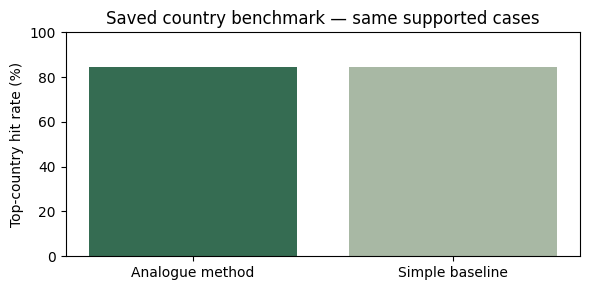

Equal to baseline: a reliable launch-first recommendation has NOT been demonstrated.


In [11]:
# Saved result from the full project's previously executed country benchmark.
# This small presentation notebook does not rerun the full catalogue-entry backtest.
SAVED_COUNTRY_RESULT = {'neighbors': 8, 'role': 'test', 'total': 28, 'supported': 26, 'coverage': 0.9285714285714286, 'topCountryHitRate': 0.8461538461538461, 'baselineHitRate': 0.8461538461538461, 'unitMAE': 434.12123463368175, 'baselineUnitMAE': 610.2564102564103}
display(pd.DataFrame([{
    "Supported new-product cases": SAVED_COUNTRY_RESULT["supported"],
    "Country hit rate (%)": 100*SAVED_COUNTRY_RESULT["topCountryHitRate"],
    "Same-case baseline (%)": 100*SAVED_COUNTRY_RESULT["baselineHitRate"]
}]).round(2))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Analogue method", "Simple baseline"],
       [100*SAVED_COUNTRY_RESULT["topCountryHitRate"], 100*SAVED_COUNTRY_RESULT["baselineHitRate"]], color=["#356c52", "#a8b8a4"])
ax.set(ylim=(0, 100), ylabel="Top-country hit rate (%)", title="Saved country benchmark — same supported cases")
plt.tight_layout(); plt.show()
print("Equal to baseline: a reliable launch-first recommendation has NOT been demonstrated.")

## 8. What to explain to sir

1. **Problem:** support product–country sales planning and evidence-based launch pilots.
2. **Real data:** the verified UCI workbook; no synthetic training rows.
3. **Training:** only past sales features; two actual gradient-boosting fits; chronological partitions.
4. **Result:** compare unit errors with a simple baseline. The validation-winning challenger worsens the later known benchmark, so the existing model is retained. Bulk-order errors remain a weakness.
5. **Launch feature:** visible comparable products and historical country scenarios; the country method ties its baseline, so it is not a proven country-selection model.
6. **Limit:** records end in 2011, stockouts and promotions are unknown, and the historical test has been reused. Recent independent company records are needed to establish future accuracy.

**Conclusion:** a working, explainable ML prototype with measured results and clear boundaries; not a claim of high accuracy or guaranteed launch success.

In [12]:
# Confirm that this simplified training reproduces the original project models.
PROJECT_REFERENCE = {'Last 28 days': {'mae': 120.23493670886076, 'wape': 0.45536811786521747, 'rmse': 286.9775715666269, 'rows': 1975}, 'Gradient boosting (log units)': {'mae': 118.32735212285125, 'wape': 0.4481434856046023, 'rmse': 357.3353758941388, 'rows': 1975}, 'History boosting (absolute error)': {'mae': 129.47463014789986, 'wape': 0.4903617888077561, 'rmse': 386.26743879577884, 'rows': 1975}}
for shown, original in [(BASELINE, "Last 28 days"), (EXISTING, "Gradient boosting (log units)"),
                        (CHALLENGER, "History boosting (absolute error)")]:
    measured = metrics(*results[shown][-1])
    for key in ["mae", "wape", "rmse"]:
        assert np.isclose(measured[key], PROJECT_REFERENCE[original][key], rtol=1e-7), (shown, key)

result_table.to_csv(OUTPUT_ROOT/"model_results.csv", index=False)
case_table.to_csv(OUTPUT_ROOT/"case_results.csv", index=False)
scenario_table.to_csv(OUTPUT_ROOT/"new_product_scenario.csv", index=False)
print("Verified: all three methods reproduce the project's benchmark errors.")
print("Saved results to:", OUTPUT_ROOT)

Verified: all three methods reproduce the project's benchmark errors.
Saved results to: D:\AML\SmartRetailing\artifacts\presentation-run
